# DTU dataset, high reverberation: forward models

Converging evidence from an independent two-talker EEG dataset: Fuglsang, Dau & Hjortkjaer 2017, NeuroImage 156:435-444 (Zenodo 1199011; 18 subjects, 64-channel EEG, two talkers at +-60 degrees, attend one). That paper decoded attention; here the same data go through the forward models of this project, cell for cell as `diotic.ipynb`.

**How the data were prepared** (`dtu/dtu_pipeline.py`, on the cluster; run from `dtu.ipynb`), aligned with this project step for step:
- EEG: the raw recordings, preprocessed as this project's pipeline: bad channels by neighbour correlation, 0.5-20 Hz, mastoid reference, extended-infomax ICA with ICLabel (eye blinks, heart beats at >= 0.9), 64 Hz; trials cut at the trigger events as the authors' script does
- Trials: from the authors' trial table (stories, attended talker, single or two talkers, room)
- Predictors: 8-band gammatone envelope and onsets, made exactly as this project's; the mixture from the two stories summed (the rooms were simulated at presentation, so the exact mixture at the ears is not available)
- TRFs: the same boosting settings (-100 to 400 ms, 50 ms basis, l1, cross-validated)
- Tests: as this project's two-talker notebooks

**ROI:** this project's clean-speech ROI (`roi.txt`), found from the cocktail clean-speech whole-scalp tests (`clean.ipynb`). Every model test below runs within it (one-tailed TFCE in the ROI, and the ROI-averaged t-test), as in this project's two-talker notebooks, and every response function is averaged over it.

**Results come from the cluster**: run `dtu_run()` in `dtu.ipynb` first; this notebook only reads them.

In [66]:
# Reloads the code every time it runs, so changes pulled from GitHub take effect without
# restarting the kernel (Run All is enough).
import importlib, sys
for _module in ('experiment', 'parameters'):
    if getattr(sys.modules.get(_module), '__spec__', None):
        importlib.reload(sys.modules[_module])
from parameters import *

## DTU, high reverberation

In [67]:
# Reads this room's results from the cluster and sets the ROI: this project's clean-speech ROI (roi.txt),
# found from the cocktail clean-speech whole-scalp tests. Every test below runs within it.
ROI = dtu_setup('high')

DTU high: 18 subjects, 20 trials of 50 s each.
Primary ROI, this project's clean-speech ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Sensitivity B, the DTU ROI (39 sensors; conjunction: significant for every predictor): AF3, F1, F3, F5, F7, FC5, FC3, FC1, C1, C3, C5, CP3, CP1, P1, PO3, Oz, CPz, Fpz, Fp2, AF8, AF4, AFz, Fz, F2, F4, F6, F8, FT8, FC6, FC4, FC2, FCz, Cz, C2, C4, C6, T8, CP4, CP2
Sensitivity C: the whole scalp (64 sensors)


In [68]:
# All subjects' full-model TRFs, with the same columns as the cocktail notebooks' data_full
data_full = dtu_trfs('high')

<small>

**Stream-level tests: each stream's envelope + onsets removed together**

- A stream = one talker's (or the mixture's) envelope + onsets
- Asks whether the brain tracks that stream at all, beyond the other two
- Can be significant when neither the envelope nor the onsets alone are

</small>

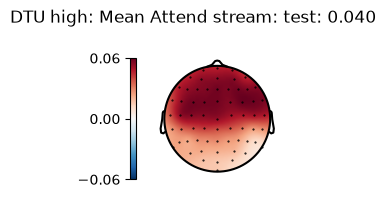

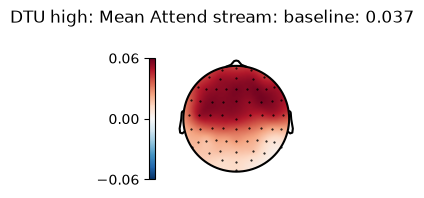

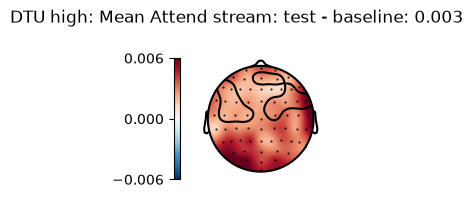

In [69]:
# Attend stream (envelope + onsets) unique contribution (DTU high)
data, diff, result = dtu_model_test('Attend stream', 'high')
show_topomap_trio(data, diff, result, 'Attend stream', 'DTU high', None)

In [70]:
display(result)
print(f"Attend stream (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Attend stream (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .001>

Attend stream (DTU high): TFCE t_max = 3.82, p = 0.001
Attend stream (DTU high): ROI model comparison t(17) = 3.729, p = 0.0008


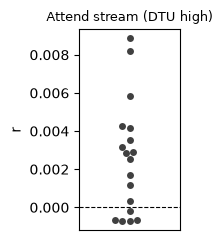

In [71]:
p = show_subject_swarm(diff, 'Attend stream', 'DTU high')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


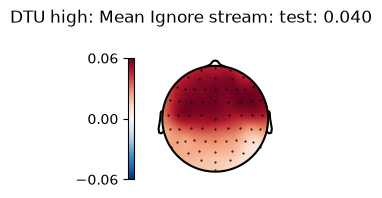

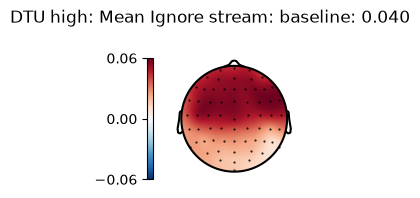

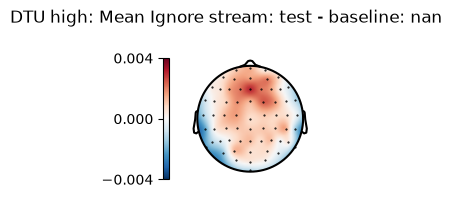

In [72]:
# Ignore stream (envelope + onsets) unique contribution (DTU high)
data, diff, result = dtu_model_test('Ignore stream', 'high')
show_topomap_trio(data, diff, result, 'Ignore stream', 'DTU high', None)

In [73]:
display(result)
print(f"Ignore stream (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Ignore stream (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .121>

Ignore stream (DTU high): TFCE t_max = 2.23, p = 0.121
Ignore stream (DTU high): ROI model comparison t(17) = 1.486, p = 0.0778


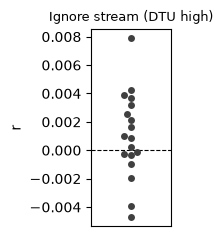

In [74]:
p = show_subject_swarm(diff, 'Ignore stream', 'DTU high')

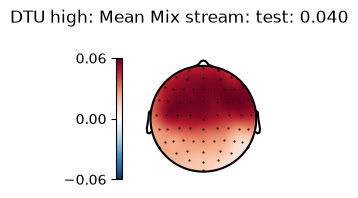

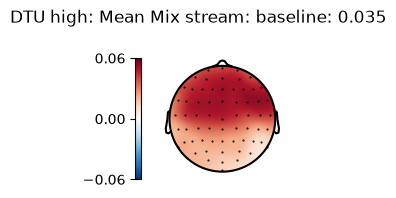

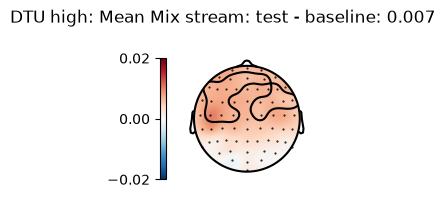

In [75]:
# Mix stream (envelope + onsets) unique contribution (DTU high)
data, diff, result = dtu_model_test('Mix stream', 'high')
show_topomap_trio(data, diff, result, 'Mix stream', 'DTU high', None)

In [76]:
display(result)
print(f"Mix stream (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Mix stream (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Mix stream (DTU high): TFCE t_max = 5.98, p < 0.001
Mix stream (DTU high): ROI model comparison t(17) = 5.983, p = 0.0000


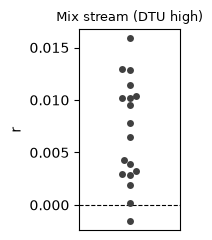

In [77]:
p = show_subject_swarm(diff, 'Mix stream', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, onset attend unique contribution**

- Attended onsets add predictive power: t_max = 6.32, p < 0.001
- All tests here are within the auditory cortex region
- Best overall model fit: r = 0.158

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


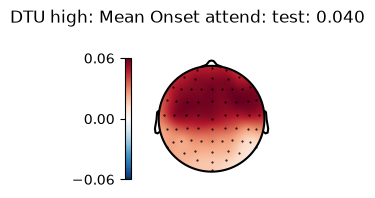

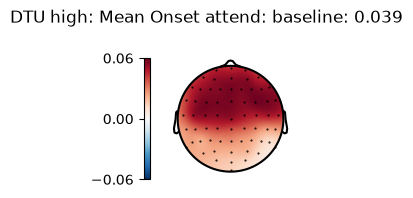

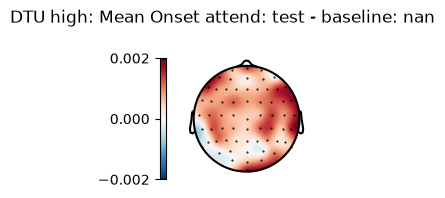

In [78]:
# Onset attend unique contribution (DTU high)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = dtu_model_test('Onset attend', 'high')
show_topomap_trio(data, diff, result, 'Onset attend', 'DTU high', None)

In [79]:
display(result)
print(f"Onset attend (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .076>

Onset attend (DTU high): TFCE t_max = 2.46, p = 0.076
Onset attend (DTU high): ROI model comparison t(17) = 2.217, p = 0.0203


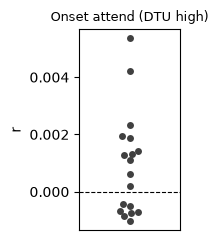

In [80]:
p = show_subject_swarm(diff, 'Onset attend', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, onset ignore unique contribution**

- Ignored onsets add predictive power: t_max = 6.70, p < 0.001
- Key finding: the ignored speaker is represented even after accounting for the mixture and the attended speaker

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


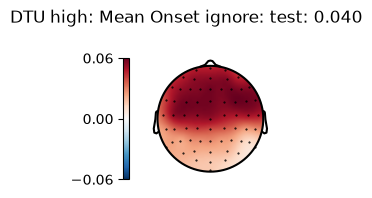

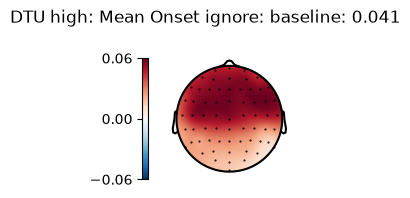

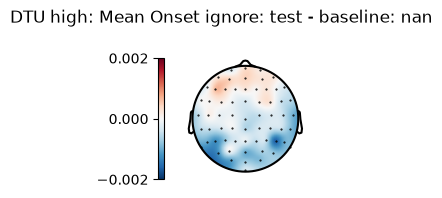

In [81]:
# Onset ignore unique contribution (DTU high)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = dtu_model_test('Onset ignore', 'high')
show_topomap_trio(data, diff, result, 'Onset ignore', 'DTU high', None)

In [82]:
display(result)
print(f"Onset ignore (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .365>

Onset ignore (DTU high): TFCE t_max = 1.64, p = 0.365
Onset ignore (DTU high): ROI model comparison t(17) = 0.297, p = 0.3850


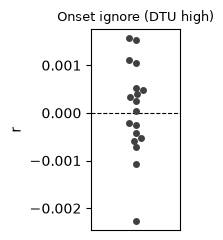

In [83]:
p = show_subject_swarm(diff, 'Onset ignore', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, onset mix unique contribution**

- Mixture onsets add predictive power: t_max = 8.61, p < 0.001

</small>

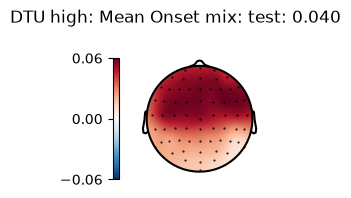

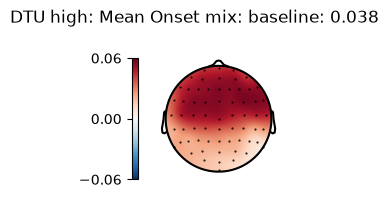

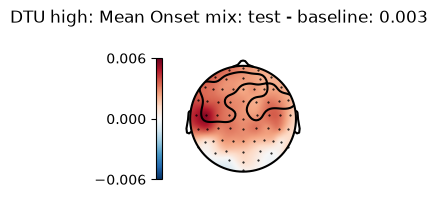

In [84]:
# Onset mix unique contribution (DTU high)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = dtu_model_test('Onset mix', 'high')
show_topomap_trio(data, diff, result, 'Onset mix', 'DTU high', None)

In [85]:
display(result)
print(f"Onset mix (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset mix (DTU high): TFCE t_max = 5.18, p < 0.001
Onset mix (DTU high): ROI model comparison t(17) = 4.937, p = 0.0001


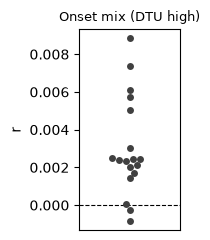

In [86]:
p = show_subject_swarm(diff, 'Onset mix', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, envelope attend unique contribution**

- Attended envelope adds predictive power: t_max = 7.37, p < 0.001

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


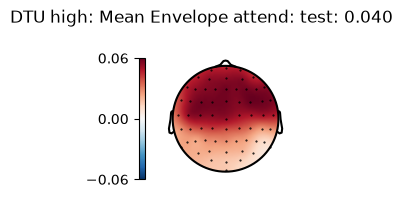

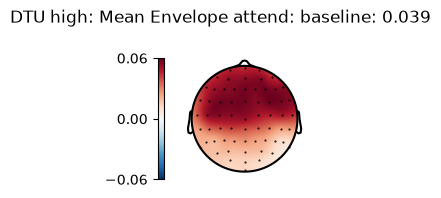

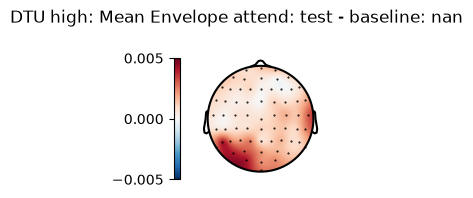

In [87]:
# Envelope attend unique contribution (DTU high)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = dtu_model_test('Envelope attend', 'high')
show_topomap_trio(data, diff, result, 'Envelope attend', 'DTU high', None)

In [88]:
display(result)
print(f"Envelope attend (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .245>

Envelope attend (DTU high): TFCE t_max = 1.83, p = 0.245
Envelope attend (DTU high): ROI model comparison t(17) = 1.420, p = 0.0869


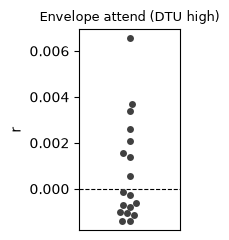

In [89]:
p = show_subject_swarm(diff, 'Envelope attend', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, envelope ignore unique contribution**

- Ignored envelope adds predictive power: t_max = 6.28, p < 0.001

</small>

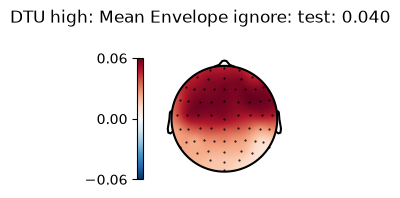

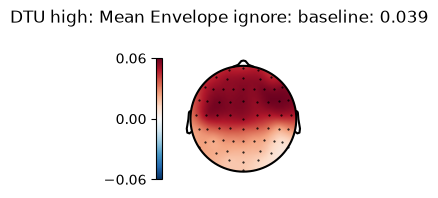

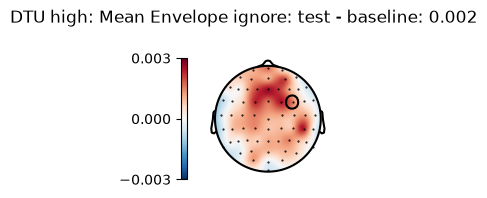

In [90]:
# Envelope ignore unique contribution (DTU high)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = dtu_model_test('Envelope ignore', 'high')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'DTU high', None)

In [91]:
display(result)
print(f"Envelope ignore (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .034>

Envelope ignore (DTU high): TFCE t_max = 3.14, p = 0.034
Envelope ignore (DTU high): ROI model comparison t(17) = 1.790, p = 0.0457


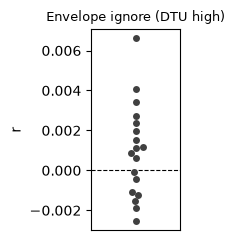

In [92]:
p = show_subject_swarm(diff, 'Envelope ignore', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, envelope mix unique contribution**

- Mixture envelope adds predictive power: t_max = 5.70, p < 0.001

</small>

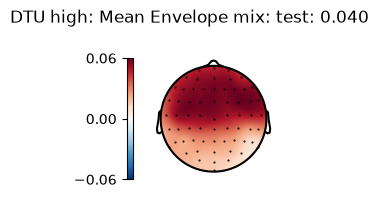

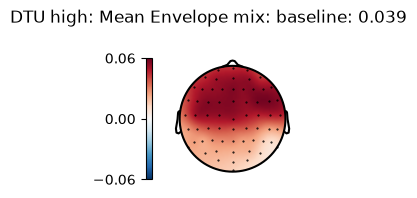

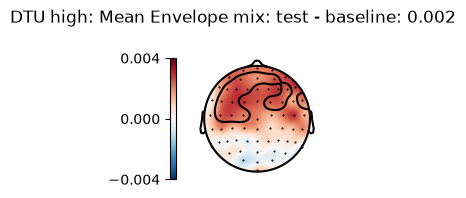

In [93]:
# Envelope mix unique contribution (DTU high)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = dtu_model_test('Envelope mix', 'high')
show_topomap_trio(data, diff, result, 'Envelope mix', 'DTU high', None)

In [94]:
display(result)
print(f"Envelope mix (DTU high): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (DTU high): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Envelope mix (DTU high): TFCE t_max = 4.71, p < 0.001
Envelope mix (DTU high): ROI model comparison t(17) = 3.583, p = 0.0011


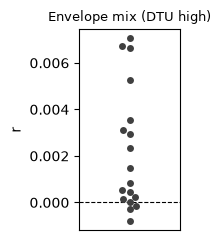

In [95]:
p = show_subject_swarm(diff, 'Envelope mix', 'DTU high')

<small>

**Brodbeck et al. 2020: Two talkers, STRFs (mix, attend, ignore)**

- Onsets: same positive-then-negative shape as for clean speech
- Positive peak: earliest and biggest for the mixture
- Negative peak: only for the mixture and the attended speaker, none for the ignored speaker
- Envelope: lower amplitude, but a strong attention effect (attended > ignored)

</small>

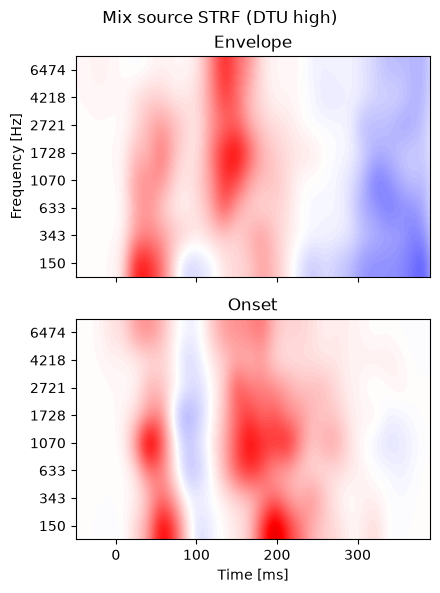

In [96]:
# Mix source STRF: envelope + onset (DTU high)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (DTU high)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

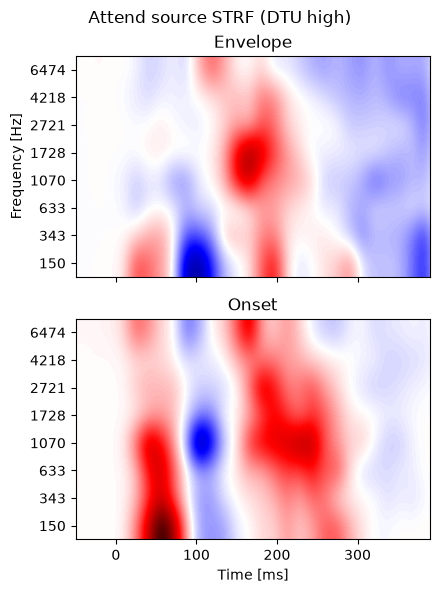

In [97]:
# Attend source STRF: envelope + onset (DTU high)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (DTU high)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

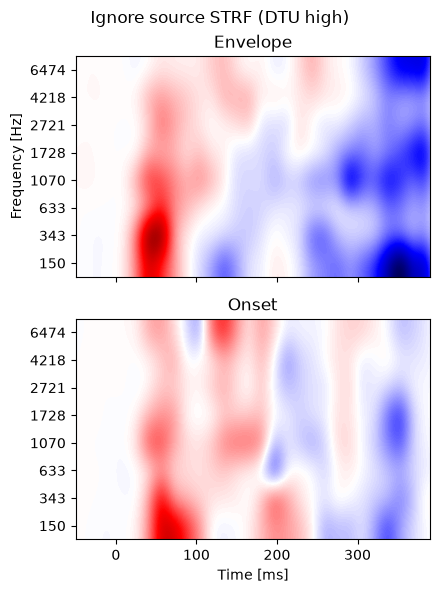

In [98]:
# Ignore source STRF: envelope + onset (DTU high)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (DTU high)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, onset peak latencies**

- Positive peak: mixture 72 ms, attended 81 ms, ignored 89 ms
- Negative peak: mixture 136 ms, attended 150 ms, ignored none
- Peak search window: 20 to 200 ms (this notebook: the same)

</small>

In [99]:
# Onset attend peak amplitude & timing (DTU high)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (DTU high) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (DTU high) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (DTU high) positive peak: 53 ms, amp 0.003072
Onset attend (DTU high) negative peak: 109 ms, amp -0.00169


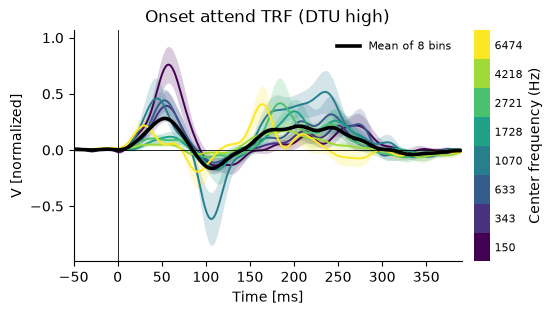

In [100]:
# Onset attend TRF per frequency bin (DTU high)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (DTU high)')

In [101]:
# Onset ignore peak amplitude & timing (DTU high)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (DTU high) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (DTU high) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (DTU high) positive peak: 58 ms, amp 0.001476
Onset ignore (DTU high) negative peak: 188 ms, amp -0.0002915


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2419: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


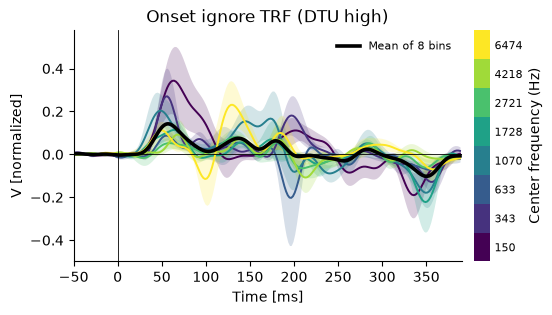

In [102]:
# Onset ignore TRF per frequency bin (DTU high)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (DTU high)')

In [103]:
# Onset mix peak amplitude & timing (DTU high)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (DTU high) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (DTU high) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (DTU high) positive peak: 184 ms, amp 0.004957
Onset mix (DTU high) negative peak: 98 ms, amp -0.001499


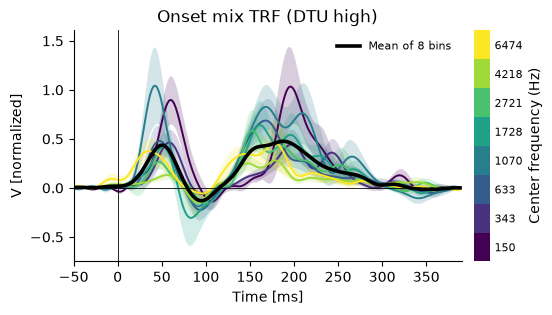

In [104]:
# Onset mix TRF per frequency bin (DTU high)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (DTU high)')

<small>

**Brodbeck et al. 2020: Two talkers, envelope peaks**

- No envelope peak latencies reported; only the attention effect (see the attention-effect cell below)

</small>

In [105]:
# Envelope attend peak amplitude & timing (DTU high)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (DTU high) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (DTU high) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (DTU high) positive peak: 178 ms, amp 0.002455
Envelope attend (DTU high) negative peak: 97 ms, amp -0.001395


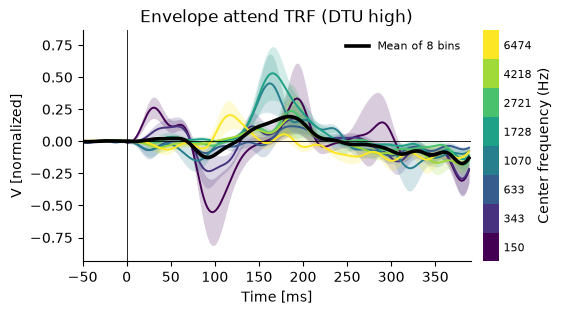

In [106]:
# Envelope attend TRF per frequency bin (DTU high)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (DTU high)')

In [107]:
# Envelope ignore peak amplitude & timing (DTU high)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (DTU high) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (DTU high) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (DTU high) positive peak: 54 ms, amp 0.001848
Envelope ignore (DTU high) negative peak: 184 ms, amp -0.0004468


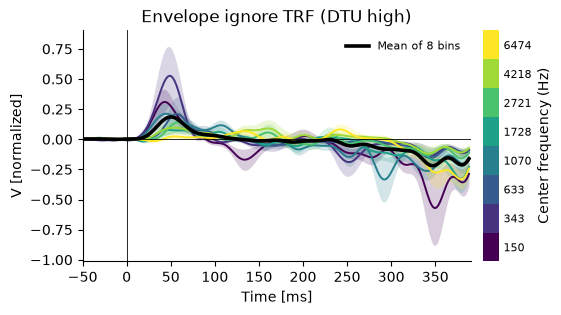

In [108]:
# Envelope ignore TRF per frequency bin (DTU high)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (DTU high)')

In [109]:
# Envelope mix peak amplitude & timing (DTU high)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (DTU high) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (DTU high) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (DTU high) positive peak: 138 ms, amp 0.005352
Envelope mix (DTU high) negative peak: 91 ms, amp -2.87e-06


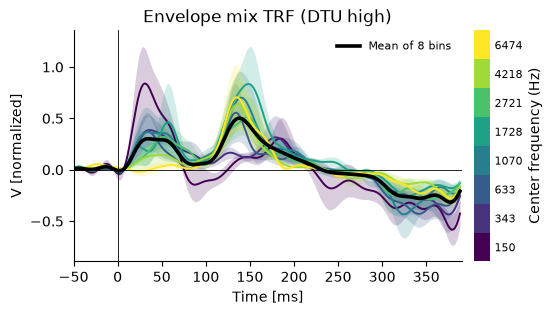

In [110]:
# Envelope mix TRF per frequency bin (DTU high)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (DTU high)')

<small>

**Brodbeck et al. 2020: Two talkers, onset peak comparison**

- Positive peak later for attended than mixture: 81 vs 72 ms, t(25) = 4.47, p < 0.001
- Positive peak later for ignored than mixture: 89 vs 72 ms, t(25) = 6.92, p < 0.001
- Positive peak bigger for mixture than attended: t(25) = 8.41, p < 0.001
- Positive peak bigger for mixture than ignored: t(25) = 7.66, p < 0.001
- Negative peak later for attended than mixture: 150 vs 136 ms, t(25) = 3.20, p = 0.004
- Negative peak amplitude: no difference (mixture vs attended), t(25) = 1.56, p = 0.132

</small>

In [111]:
# Onset peak comparison across mix, attend, and ignore (DTU high)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2419: UserWarning: negative anchor (ignore) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


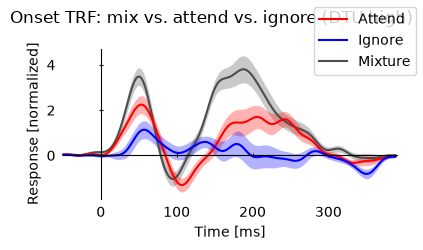

In [112]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (DTU high)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [113]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        mix                199       0.01083
S2        mix                173      0.001347
S3        mix                199      0.001379
S4        mix                175      0.005349
S5        mix                164      0.002579
S6        mix                199      0.002133
S7        mix                197      0.009341
S8        mix                179       0.00795
S9        mix                173      0.002578
S10       mix                170      0.005558
S11       mix                183     0.0009666
S12       mix                197      0.005396
S13       mix                181      0.003816
S14       mix                199      0.007772
S15       mix                164       0.00376
S16       mix                193      0.001683
S17       mix                185      0.001157
S18       mix                183       0.01564
S1        attend              56      0.004717
S2        attend              52      0.00564

In [114]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 35.21*** p < .001,t17 = 43.77*** p < .001
attend,,t17 = -1.48 p = .158


,attend,ignore
mix,t17 = -3.14** p = .006,t17 = -28.94*** p < .001
attend,,t17 = -25.28*** p < .001


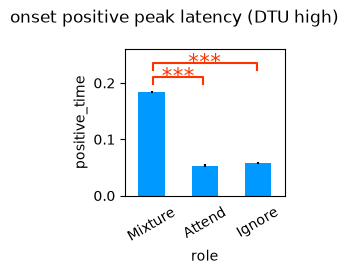

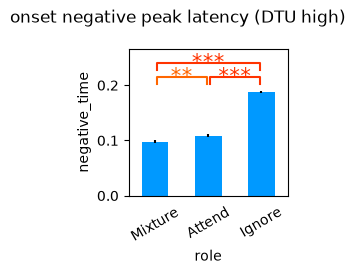

In [115]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (DTU high)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (DTU high)')
p.set_xtick_rotation(30)

In [116]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 1.89 p = .077,t17 = 4.20*** p < .001
attend,,t17 = 3.55** p = .002


,attend,ignore
mix,t17 = 0.41 p = .686,t17 = -1.75 p = .097
attend,,t17 = -1.86 p = .081


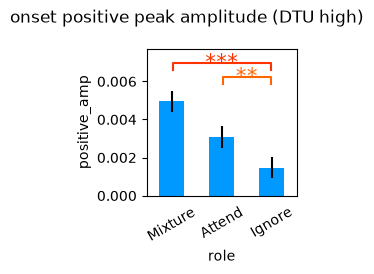

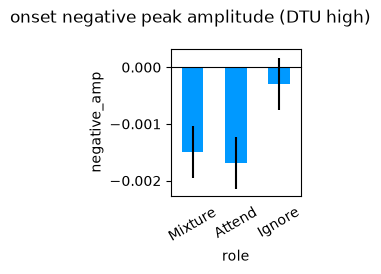

In [117]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (DTU high)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (DTU high)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope peak comparison**

- No envelope peak comparison reported

</small>

In [118]:
# Envelope peak comparison across mix, attend, and ignore (DTU high)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

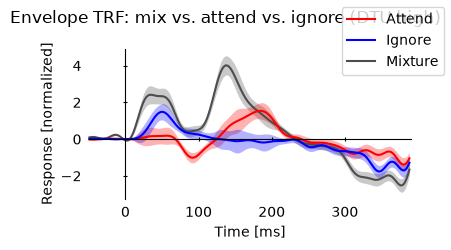

In [119]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (DTU high)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [120]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        mix                138      0.008279
S2        mix                127      0.003707
S3        mix                148     0.0004963
S4        mix                152       0.01984
S5        mix                121      0.004471
S6        mix                136      0.001367
S7        mix                132      0.002487
S8        mix                132       0.01424
S9        mix                115      0.001321
S10       mix                148      0.003963
S11       mix                162     5.796e-05
S12       mix                142      0.003607
S13       mix                144      0.003317
S14       mix                132       0.00944
S15       mix                121      0.002842
S16       mix                144      0.001788
S17       mix                162      0.005092
S18       mix                130       0.01003
S1        attend             199     0.0009543
S2        attend             162      0.00239

In [121]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = -10.04*** p < .001,t17 = 20.23*** p < .001
attend,,t17 = 30.00*** p < .001


,attend,ignore
mix,t17 = -1.71 p = .105,t17 = -16.64*** p < .001
attend,,t17 = -19.43*** p < .001


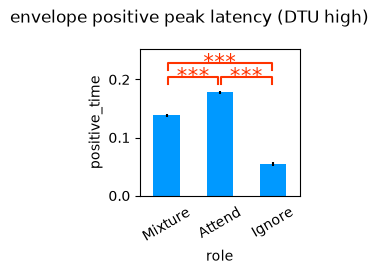

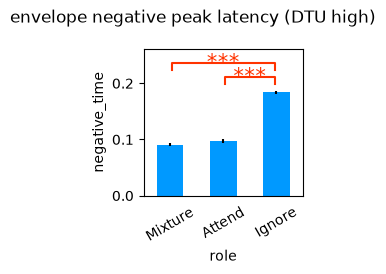

In [122]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (DTU high)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (DTU high)')
p.set_xtick_rotation(30)

In [123]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 2.20* p = .042,t17 = 2.51* p = .022
attend,,t17 = 0.58 p = .568


,attend,ignore
mix,t17 = 3.55** p = .002,t17 = 1.27 p = .220
attend,,t17 = -1.78 p = .092


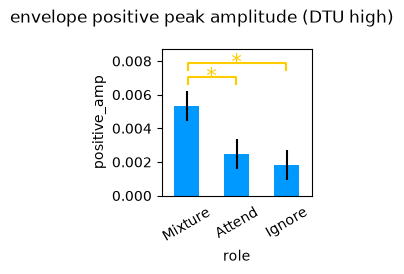

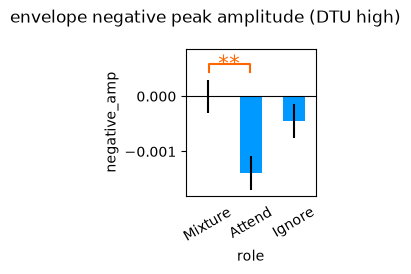

In [124]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (DTU high)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (DTU high)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope attention effect (attend - ignore)**

- Negative peak at about 100 ms
- Positive peak at about 200 ms
- The attention effect starts almost as early as the earliest response

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (DTU high): bins that differ from 0 somewhere: 1070 Hz, 2721 Hz


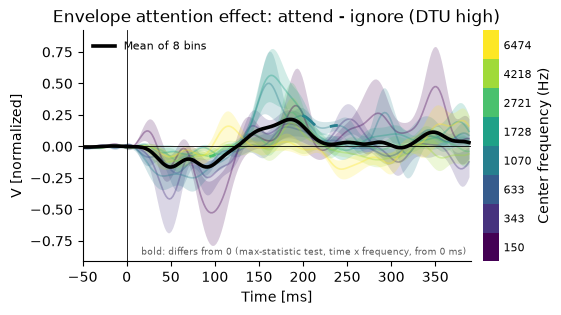

In [125]:
# Envelope attention effect: attend - ignore (DTU high)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (DTU high)', subtract='bg_gammatone_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (DTU high): no time range differs from 0 (max-statistic permutation test from 0 ms, two-tailed, smallest p = 0.105)


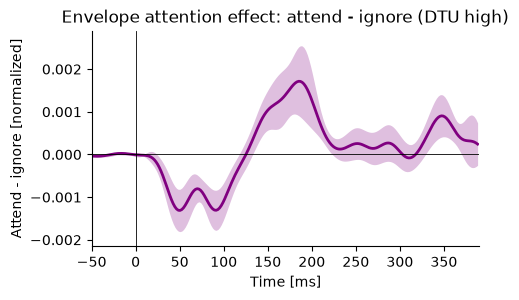

In [126]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_8', 'bg_gammatone_8', 'Envelope attention effect: attend - ignore (DTU high)')

<small>

**Brodbeck et al. 2020: Two talkers, onset attention effect (attend - ignore)**

- Early positive peak: little or no attention effect
- Later negative peak (about 136 to 150 ms): attended only, so a clear attention effect there

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (DTU high): bins that differ from 0 somewhere: 6474 Hz


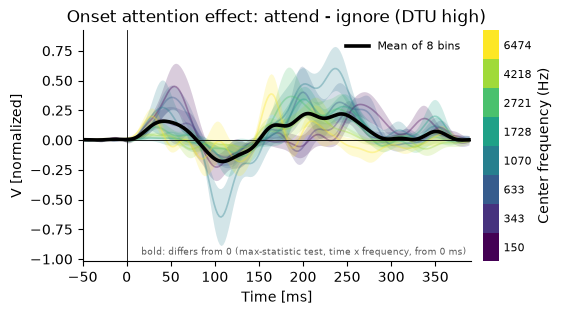

In [127]:
# Onset attention effect: attend - ignore (DTU high)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (DTU high)', subtract='bg_gammatone_on_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (DTU high): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 9-43 ms (p = 0.004)


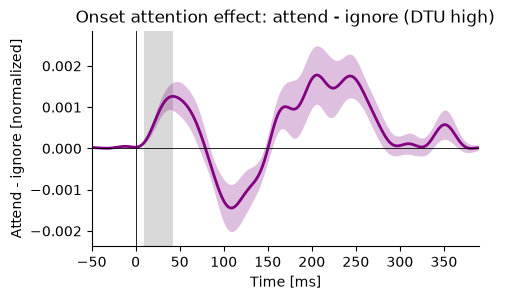

In [128]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_on_8', 'bg_gammatone_on_8', 'Onset attention effect: attend - ignore (DTU high)')